# Lab Task: Support Vector Machine (SVM)


## Task 1: Heart Disease Classification using SVM

### Step 1: Import Required Libraries

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Step 2: Load the Heart Disease Dataset


In [ ]:
from google.colab import files

uploaded = files.upload()  # Upload heart_v2.csv here

In [36]:
# Load the dataset using pandas
df = pd.read_csv('heart_v2.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
df.head()

Dataset Shape: (270, 5)

First 5 Rows:


,age,sex,BP,cholestrol,heart disease
0,70,1,130,322,1
1,67,0,115,564,0
2,57,1,124,261,1
3,64,1,128,263,0
4,74,0,120,269,0


In [37]:
# Basic dataset information
print("Dataset Info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Class Distribution:")
print(df['heart disease'].value_counts())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            270 non-null    int64
 1   sex            270 non-null    int64
 2   BP             270 non-null    int64
 3   cholestrol     270 non-null    int64
 4   heart disease  270 non-null    int64
dtypes: int64(5)
memory usage: 10.7 KB
None

Statistical Summary:
              age         sex          BP  cholestrol  heart disease
count  270.000000  270.000000  270.000000  270.000000     270.000000
mean    54.433333    0.677778  131.344444  249.659259       0.444444
std      9.109067    0.468195   17.861608   51.686237       0.497827
min     29.000000    0.000000   94.000000  126.000000       0.000000
25%     48.000000    0.000000  120.000000  213.000000       0.000000
50%     55.000000    1.000000  130.000000  245.000000       0.000000
75%     61.000000    1.000000  140.0000

### Step 3: Preprocess the Dataset

Scale features to have **zero mean and unit variance** using `StandardScaler()`.

In [38]:
# Separate features (X) and target (y)
X = df.drop(columns=['heart disease'])
y = df['heart disease']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:", list(X.columns))

Features shape: (270, 4)
Target shape: (270,)

Feature columns: ['age', 'sex', 'BP', 'cholestrol']


In [39]:
# Scale features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Features - Mean (should be ~0):", X_scaled.mean(axis=0).round(6))
print("Scaled Features - Std  (should be ~1):", X_scaled.std(axis=0).round(6))

Scaled Features - Mean (should be ~0): [ 0.  0.  0. -0.]
Scaled Features - Std  (should be ~1): [1. 1. 1. 1.]


### Step 4: Split the Dataset (80:20 Ratio)

In [40]:
# Split into training and testing sets with 80:20 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size: ", X_test.shape)

Training set size: (216, 4)
Testing set size:  (54, 4)


### Step 5: Initialize and Train the SVM Classifier

In [41]:
# Initialize SVM classifier using SVC()
svm_classifier = SVC()

# Train the classifier on the training dataset using fit()
svm_classifier.fit(X_train, y_train)

print("SVM Classifier trained successfully!")
print("Classifier Parameters:", svm_classifier.get_params())

SVM Classifier trained successfully!
Classifier Parameters: {'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


### Step 6: Make Predictions

In [42]:
# Predict target variable for the testing dataset using predict()
y_pred = svm_classifier.predict(X_test)

print("Predictions:", y_pred)
print("Actual Labels:", y_test.values)

Predictions: [1 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0
 0 1 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0]
Actual Labels: [1 1 0 0 0 1 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1 0 1 0 0 1 0 1 0 0 0 0 1 0 1 1 1
 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1]


### Step 7: Evaluate the Classifier's Performance

In [43]:
# Compute performance metrics
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

print("=" * 40)
print("       SVM Performance Metrics       ")
print("=" * 40)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("=" * 40)

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Disease', 'Heart Disease']))

       SVM Performance Metrics       
Accuracy  : 0.6481
Precision : 0.5556
Recall    : 0.4762
F1-Score  : 0.5128

Detailed Classification Report:
               precision    recall  f1-score   support

   No Disease       0.69      0.76      0.72        33
Heart Disease       0.56      0.48      0.51        21

     accuracy                           0.65        54
    macro avg       0.62      0.62      0.62        54
 weighted avg       0.64      0.65      0.64        54



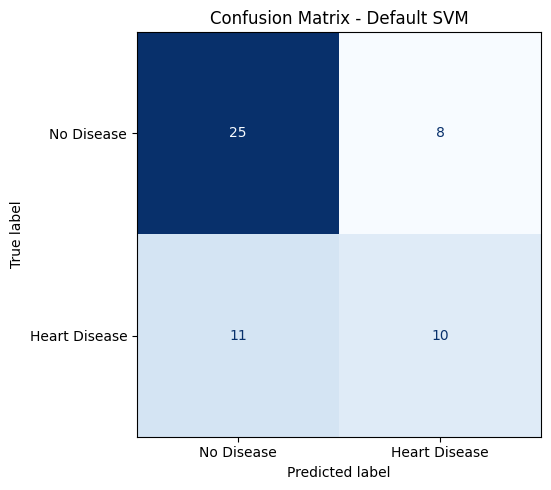

In [44]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Heart Disease'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - Default SVM')
plt.tight_layout()
plt.show()

### Step 8: Hyperparameter Experimentation

Experiment with different **kernels**, **C values**, and **gamma** to observe their effect on performance metrics.

In [45]:
# Define hyperparameter configurations to experiment with
hyperparameter_configs = [
    {'kernel': 'linear',  'C': 0.1,  'gamma': 'scale'},
    {'kernel': 'linear',  'C': 1,    'gamma': 'scale'},
    {'kernel': 'linear',  'C': 10,   'gamma': 'scale'},
    {'kernel': 'rbf',     'C': 0.1,  'gamma': 'scale'},
    {'kernel': 'rbf',     'C': 1,    'gamma': 'scale'},
    {'kernel': 'rbf',     'C': 10,   'gamma': 'scale'},
    {'kernel': 'rbf',     'C': 1,    'gamma': 0.1},
    {'kernel': 'rbf',     'C': 1,    'gamma': 0.01},
    {'kernel': 'poly',    'C': 1,    'gamma': 'scale'},
    {'kernel': 'sigmoid', 'C': 1,    'gamma': 'scale'},
]

results = []

for config in hyperparameter_configs:
    clf = SVC(kernel=config['kernel'], C=config['C'], gamma=config['gamma'], random_state=42)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    results.append({
        'Kernel':    config['kernel'],
        'C':         config['C'],
        'Gamma':     str(config['gamma']),
        'Accuracy':  round(accuracy_score(y_test, preds),  4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall':    round(recall_score(y_test, preds),    4),
        'F1-Score':  round(f1_score(y_test, preds),        4),
    })

results_df = pd.DataFrame(results)
print("Hyperparameter Experimentation Results:")
results_df

Hyperparameter Experimentation Results:


,Kernel,C,Gamma,Accuracy,Precision,Recall,F1-Score
0,linear,0.1,scale,0.7037,0.6471,0.5238,0.5789
1,linear,1.0,scale,0.7037,0.6471,0.5238,0.5789
2,linear,10.0,scale,0.7037,0.6471,0.5238,0.5789
3,rbf,0.1,scale,0.7222,0.7500,0.4286,0.5455
4,rbf,1.0,scale,0.6481,0.5556,0.4762,0.5128
5,rbf,10.0,scale,0.5556,0.4286,0.4286,0.4286
6,rbf,1.0,0.1,0.6667,0.5882,0.4762,0.5263
7,rbf,1.0,0.01,0.7037,0.6667,0.4762,0.5556
8,poly,1.0,scale,0.6852,0.7000,0.3333,0.4516
9,sigmoid,1.0,scale,0.7222,0.6667,0.5714,0.6154


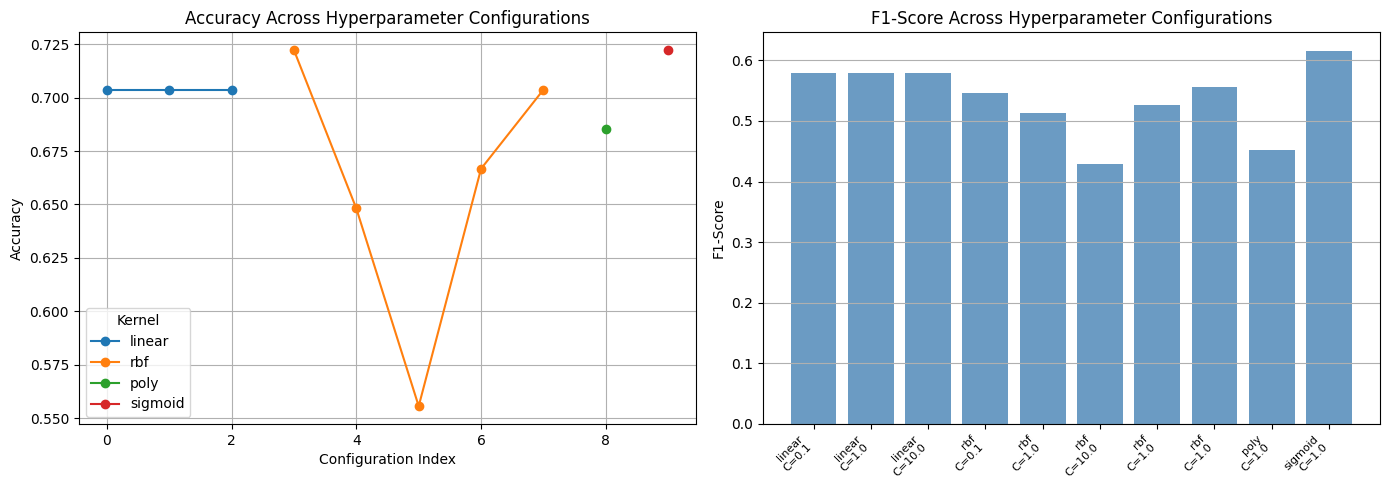

In [46]:
# Visualize hyperparameter effect on Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Group by Kernel
for kernel in results_df['Kernel'].unique():
    subset = results_df[results_df['Kernel'] == kernel]
    axes[0].plot(subset.index, subset['Accuracy'], marker='o', label=kernel)

axes[0].set_title('Accuracy Across Hyperparameter Configurations')
axes[0].set_xlabel('Configuration Index')
axes[0].set_ylabel('Accuracy')
axes[0].legend(title='Kernel')
axes[0].grid(True)

# F1-Score bar chart
labels = [f"{r['Kernel']}\nC={r['C']}" for _, r in results_df.iterrows()]
axes[1].bar(range(len(results_df)), results_df['F1-Score'], color='steelblue', alpha=0.8)
axes[1].set_xticks(range(len(results_df)))
axes[1].set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
axes[1].set_title('F1-Score Across Hyperparameter Configurations')
axes[1].set_ylabel('F1-Score')
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()

In [47]:
# Best configuration
best = results_df.loc[results_df['Accuracy'].idxmax()]
print("Best Hyperparameter Configuration:")
print(best)

Best Hyperparameter Configuration:
Kernel          rbf
C               0.1
Gamma         scale
Accuracy     0.7222
Precision      0.75
Recall       0.4286
F1-Score     0.5455
Name: 3, dtype: object


---
## Task 2: Color Classification using SVM (Image Dataset)

**Dataset:** [Color Classification – Kaggle](https://www.kaggle.com/datasets/ayanzadeh93/color-classification)

- Load images with **OpenCV (`cv2`)**
- Resize every image to **32×32 pixels**
- Flatten to a 1-D vector of **3072 features** (32×32×3) and normalize by dividing by 255
- Apply **`StandardScaler`** then train `SVC` — evaluating all metrics required by the lab manual


### Step 1: Import Additional Libraries

In [48]:
import os, zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Install tqdm if not present
try:
    from tqdm import tqdm
except ImportError:
    !pip install -q tqdm
    from tqdm import tqdm


### Step 2: Load and Preprocess the Dataset

> **How to upload your dataset:**
>
> 1. On your PC, create a new folder called `color_upload`
> 2. Copy only these 9 color folders into it: **Black, Blue, Brown, Green, Orange, Red, Violet, White, Yellow**  
>    (ignore mask_* folders, testimg, ColorClassification folder, and text files)
> 3. Right-click `color_upload` → **Send to → Compressed (zipped) folder** → produces `color_upload.zip`
> 4. Run the cell below and upload `color_upload.zip` when prompted


In [ ]:
from google.colab import files

print('Please upload your color_upload.zip file:')
uploaded_zip = files.upload()

zip_name = list(uploaded_zip.keys())[0]
extract_path = '/content/color_dataset'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall(extract_path)

print(f'Extracted to: {extract_path}')
print('Contents:', os.listdir(extract_path))


In [50]:
# Detect the 9 color class folders
KNOWN_COLORS = ['Black', 'Blue', 'Brown', 'Green', 'Orange', 'Red', 'Violet', 'White', 'Yellow']

def find_color_folders(base_path, known_colors):
    found = {}
    for root, dirs, _ in os.walk(base_path):
        for d in dirs:
            if d.lower() in [c.lower() for c in known_colors]:
                found[d.lower()] = os.path.join(root, d)
    return found

color_folders = find_color_folders(extract_path, KNOWN_COLORS)
class_names   = sorted(color_folders.keys())   # alphabetical

print(f'Found {len(color_folders)} color class folder(s):')
for name, path in sorted(color_folders.items()):
    imgs = [f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    print(f'  {name:10s} -> {len(imgs):4d} images')


Found 9 color class folder(s):
  black      ->   11 images
  blue       ->   10 images
  brown      ->   20 images
  green      ->    7 images
  orange     ->   10 images
  red        ->   12 images
  violet     ->   20 images
  white      ->   17 images
  yellow     ->   10 images


Loading images: 100%|██████████| 9/9 [00:00<00:00, 31.94it/s]


Total samples loaded: 117


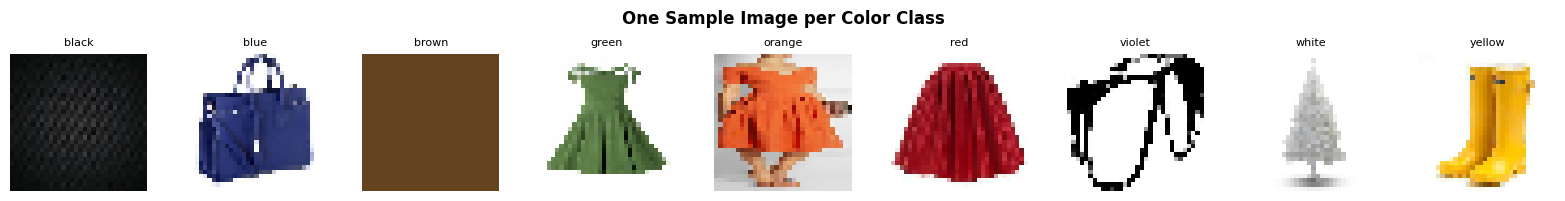

In [51]:
# -----------------------------------------------------------------------
# Feature Extraction  (mirrors reference implementation)
# Each image -> resized to 32x32 -> flattened to 3072 features -> /255
# -----------------------------------------------------------------------
IMG_SIZE = 32   # smaller than 1280 used in reference but same pixel approach

training_data = []

def create_training_data(color_folders, class_names, img_size):
    for cls_name in tqdm(class_names, desc='Loading images'):
        folder = color_folders[cls_name]
        class_num = class_names.index(cls_name)
        for img_file in os.listdir(folder):
            try:
                img_array = cv2.imread(os.path.join(folder, img_file))
                img_array = cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB)  # BGR->RGB
                new_array = cv2.resize(img_array, (img_size, img_size))
                training_data.append([new_array, class_num])
            except Exception:
                pass

create_training_data(color_folders, class_names, IMG_SIZE)
print(f'Total samples loaded: {len(training_data)}')

# Show one sample image per class
fig, axes = plt.subplots(1, len(class_names), figsize=(16, 2))
shown = {}
for img_arr, lbl in training_data:
    if lbl not in shown:
        axes[lbl].imshow(img_arr)
        axes[lbl].set_title(class_names[lbl], fontsize=8)
        axes[lbl].axis('off')
        shown[lbl] = True
    if len(shown) == len(class_names):
        break
plt.suptitle('One Sample Image per Color Class', fontweight='bold')
plt.tight_layout()
plt.show()


In [52]:
import random
random.shuffle(training_data)

X_color = []
y_color = []

for features, label in training_data:
    X_color.append(features)
    y_color.append(label)

# Reshape to (n_samples, 32*32*3) and normalize to [0, 1]
X_color = np.array(X_color).reshape(len(X_color), -1)  # flatten
X_color = X_color / 255.0                               # normalize
y_color = np.array(y_color)

print('Feature matrix shape:', X_color.shape,
      f'  ({IMG_SIZE}x{IMG_SIZE}x3 = {IMG_SIZE*IMG_SIZE*3} features per image)')
print('Label array shape   :', y_color.shape)
print('Classes             :', class_names)

# Class distribution
color_df = pd.DataFrame({'label': [class_names[i] for i in y_color]})
print('\nClass Distribution:')
print(color_df['label'].value_counts())


Feature matrix shape: (117, 3072)   (32x32x3 = 3072 features per image)
Label array shape   : (117,)
Classes             : ['black', 'blue', 'brown', 'green', 'orange', 'red', 'violet', 'white', 'yellow']

Class Distribution:
label
violet    20
brown     20
white     17
red       12
black     11
blue      10
orange    10
yellow    10
green      7
Name: count, dtype: int64


In [53]:
# Scale features to zero mean and unit variance using StandardScaler
scaler_color = StandardScaler()
X_color_scaled = scaler_color.fit_transform(X_color)

print('Scaled Mean sample (first 5 features, should be ~0):',
      X_color_scaled.mean(axis=0)[:5].round(4))
print('Scaled Std  sample (first 5 features, should be ~1):',
      X_color_scaled.std(axis=0)[:5].round(4))


Scaled Mean sample (first 5 features, should be ~0): [ 0. -0. -0.  0. -0.]
Scaled Std  sample (first 5 features, should be ~1): [1. 1. 1. 1. 1.]


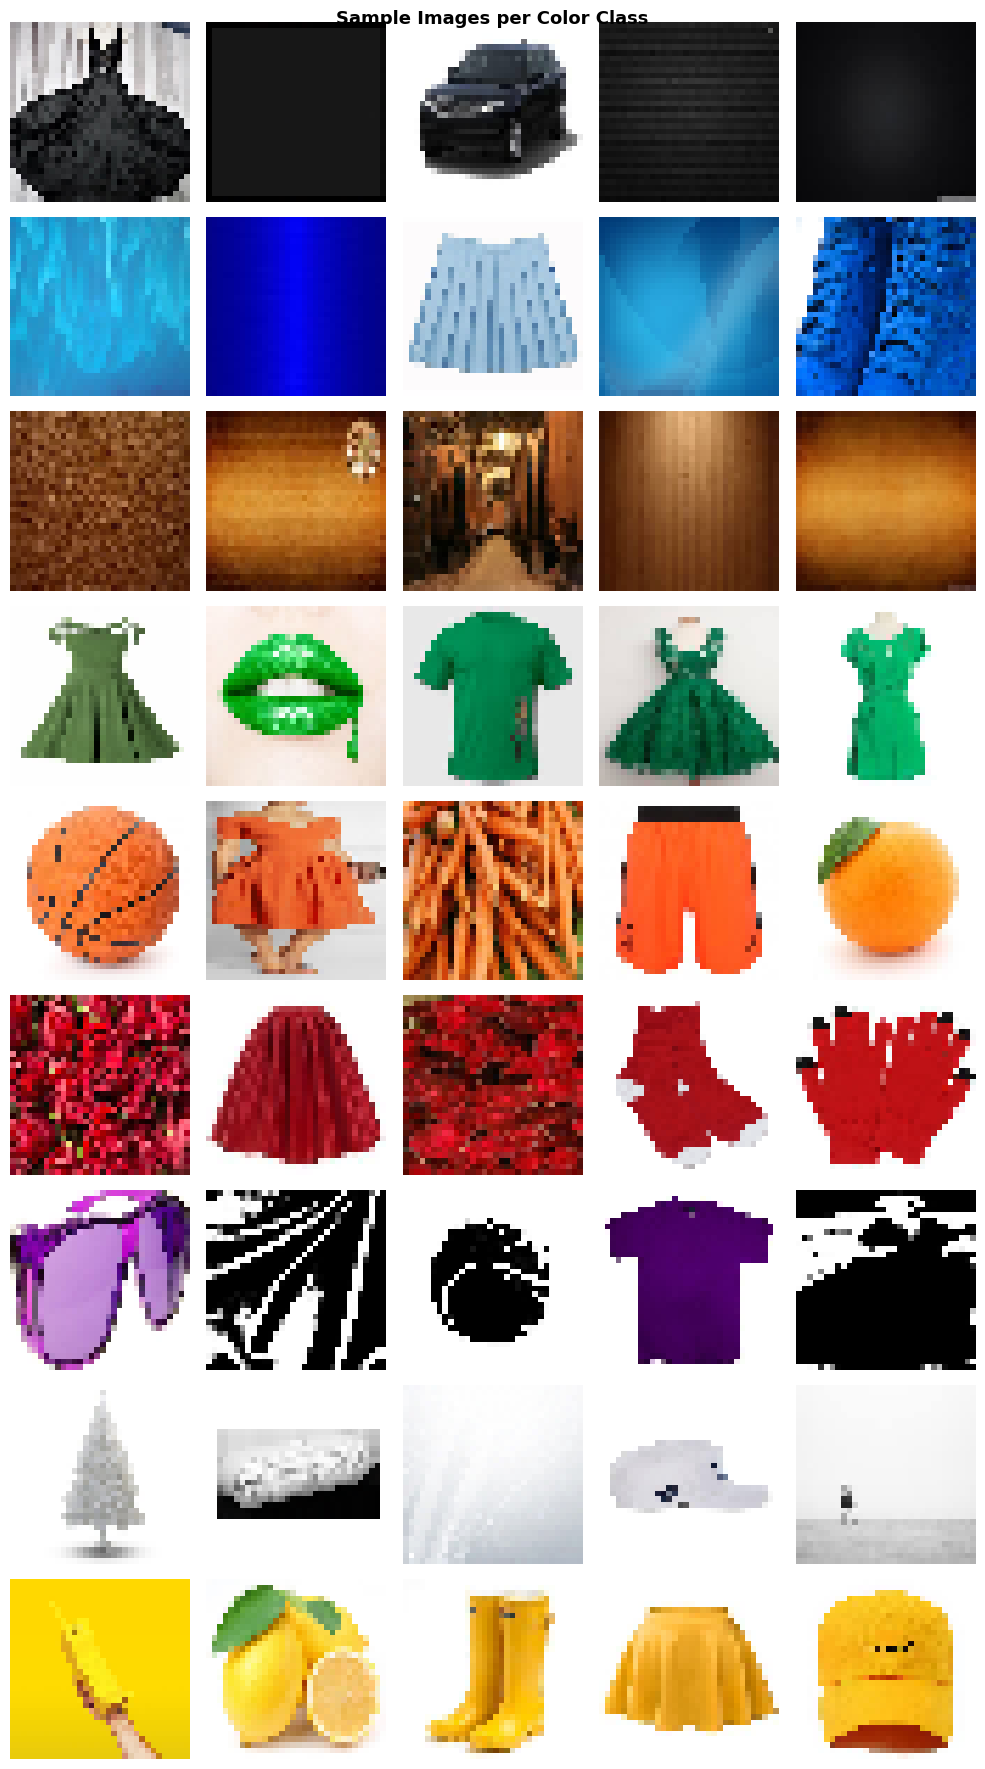

In [54]:
# Visualize random sample images from each class
n_per_class = 5
fig, axes = plt.subplots(len(class_names), n_per_class,
                         figsize=(n_per_class * 2, len(class_names) * 2))

for cls_idx, cls_name in enumerate(class_names):
    indices = [i for i, lbl in enumerate(y_color) if lbl == cls_idx]
    picks   = random.sample(indices, min(n_per_class, len(indices)))
    for col, idx in enumerate(picks):
        img = X_color[idx].reshape(IMG_SIZE, IMG_SIZE, 3)
        axes[cls_idx][col].imshow(img)
        axes[cls_idx][col].axis('off')
        if col == 0:
            axes[cls_idx][col].set_ylabel(cls_name, fontsize=9, rotation=0,
                                          labelpad=40, va='center')

plt.suptitle('Sample Images per Color Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Step 3: Train the SVM Classifier

In [55]:
# Split dataset — 80% train, 20% test
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_color_scaled, y_color, test_size=0.20, random_state=42
)

print('Training set size:', X_c_train.shape)
print('Testing set size: ', X_c_test.shape)


Training set size: (93, 3072)
Testing set size:  (24, 3072)


In [56]:
# Train SVM using One-vs-One strategy
model = OneVsOneClassifier(SVC(kernel='linear', C=1, random_state=42))
model.fit(X_c_train, y_c_train)

print('OneVsOne SVM Classifier trained successfully!')


OneVsOne SVM Classifier trained successfully!


### Step 4: Evaluate the Model

In [57]:
# Predict on the test set
y_c_pred = model.predict(X_c_test)

# Compute all four metrics required by the lab manual
accuracy_c  = accuracy_score(y_c_test, y_c_pred)
precision_c = precision_score(y_c_test, y_c_pred, average='weighted')
recall_c    = recall_score(y_c_test, y_c_pred, average='weighted')
f1_c        = f1_score(y_c_test, y_c_pred, average='weighted')

print('=' * 48)
print('   Color SVM — Performance Metrics')
print('=' * 48)
print(f'Accuracy  : {accuracy_c:.4f}')
print(f'Precision : {precision_c:.4f}  (weighted avg)')
print(f'Recall    : {recall_c:.4f}  (weighted avg)')
print(f'F1-Score  : {f1_c:.4f}  (weighted avg)')
print('=' * 48)

# Derive the classes actually present in test predictions
unique_labels      = sorted(set(y_c_test) | set(y_c_pred))
active_class_names = [class_names[i] for i in unique_labels]

# Detailed per-class classification report
print('\nDetailed Classification Report:')
print(classification_report(
    y_c_test, y_c_pred,
    labels=unique_labels,
    target_names=active_class_names
))

# Store results in a DataFrame
result = pd.DataFrame({'original': y_c_test, 'predicted': y_c_pred})
result['original_label']  = result['original'].apply(lambda i: class_names[i])
result['predicted_label'] = result['predicted'].apply(lambda i: class_names[i])
print('\nPrediction Results Table (first 10 rows):')
result.head(10)

   Color SVM — Performance Metrics
Accuracy  : 0.8750
Precision : 0.8917  (weighted avg)
Recall    : 0.8750  (weighted avg)
F1-Score  : 0.8685  (weighted avg)

Detailed Classification Report:
              precision    recall  f1-score   support

       black       1.00      1.00      1.00         1
        blue       0.50      0.50      0.50         2
       brown       0.80      1.00      0.89         4
       green       1.00      0.67      0.80         3
      orange       1.00      1.00      1.00         2
         red       1.00      0.50      0.67         2
      violet       1.00      1.00      1.00         4
       white       0.80      1.00      0.89         4
      yellow       1.00      1.00      1.00         2

    accuracy                           0.88        24
   macro avg       0.90      0.85      0.86        24
weighted avg       0.89      0.88      0.87        24


Prediction Results Table (first 10 rows):


,original,predicted,original_label,predicted_label
0,6,6,violet,violet
1,4,4,orange,orange
2,4,4,orange,orange
3,2,2,brown,brown
4,3,3,green,green
5,2,2,brown,brown
6,5,2,red,brown
7,3,3,green,green
8,6,6,violet,violet
9,1,7,blue,white


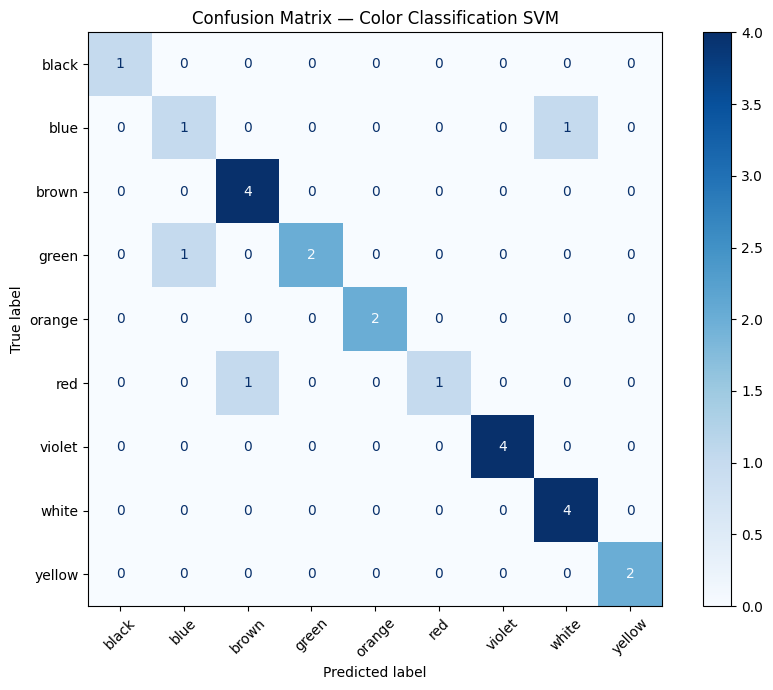

In [58]:
# Confusion Matrix
unique_labels      = sorted(set(y_c_test) | set(y_c_pred))
active_class_names = [class_names[i] for i in unique_labels]

cm_color   = confusion_matrix(y_c_test, y_c_pred, labels=unique_labels)
disp_color = ConfusionMatrixDisplay(confusion_matrix=cm_color,
                                    display_labels=active_class_names)

fig, ax = plt.subplots(figsize=(9, 7))
disp_color.plot(ax=ax, cmap='Blues', colorbar=True, xticks_rotation=45)
plt.title('Confusion Matrix — Color Classification SVM')
plt.tight_layout()
plt.show()

### Step 5: Visualize Results — Decision Boundaries & Sample Predictions

Because the feature space has 3072 dimensions, decision boundaries are visualized using **PCA** to reduce to 2D, then a fresh 2D SVM is trained on those components for the boundary plot.

Explained variance by 2 PCA components: 61.6%


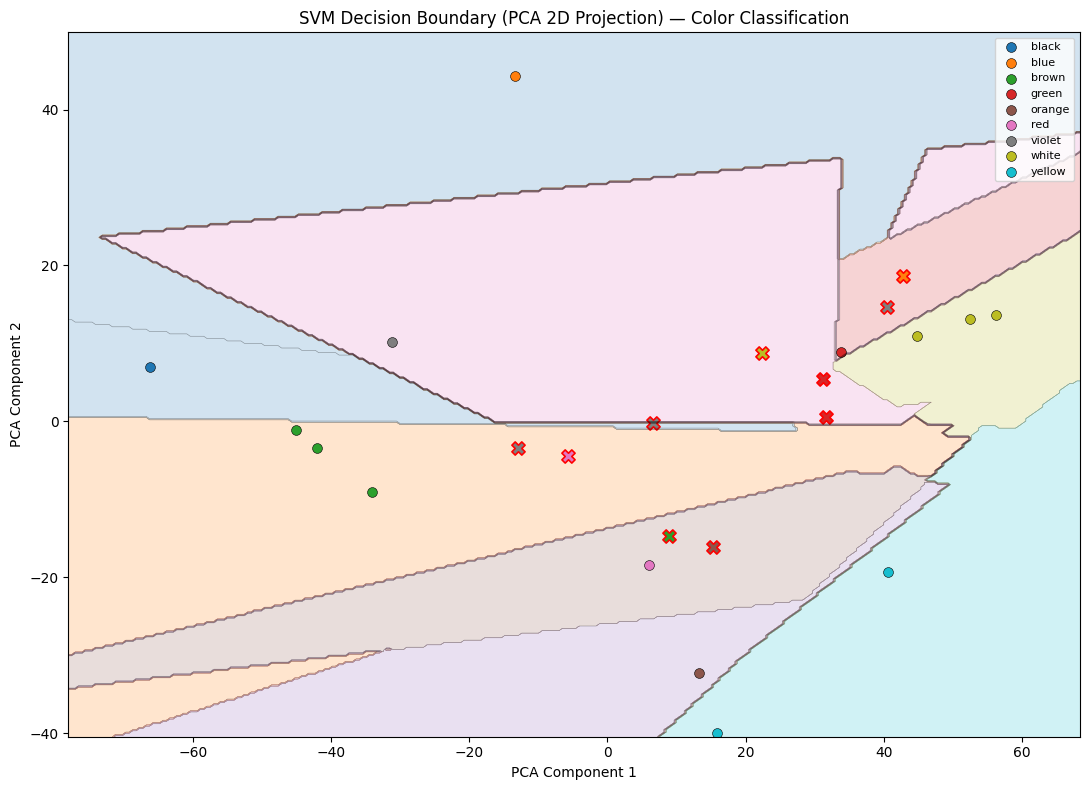

Legend: o = correctly classified  |  X (red border) = misclassified


In [59]:
from sklearn.decomposition import PCA

# Reduce to 2D with PCA for decision boundary visualization
pca = PCA(n_components=2, random_state=42)
X_c_train_2d = pca.fit_transform(X_c_train)
X_c_test_2d  = pca.transform(X_c_test)

print(f'Explained variance by 2 PCA components: '
      f'{pca.explained_variance_ratio_.sum()*100:.1f}%')

# Train a 2D SVM on the PCA-reduced training data for visualization
svm_2d = SVC(kernel='linear', C=1, random_state=42)
svm_2d.fit(X_c_train_2d, y_c_train)
y_c_pred_2d = svm_2d.predict(X_c_test_2d)

# Build the decision boundary mesh
x_min, x_max = X_c_train_2d[:, 0].min()-1, X_c_train_2d[:, 0].max()+1
y_min, y_max = X_c_train_2d[:, 1].min()-1, X_c_train_2d[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

tab10 = plt.cm.tab10(np.linspace(0, 1, len(class_names)))

fig, ax = plt.subplots(figsize=(11, 8))
ax.contourf(xx, yy, Z, alpha=0.2, cmap='tab10')
ax.contour(xx, yy, Z, colors='k', linewidths=0.4, alpha=0.4)

for cls_idx, cls_name in enumerate(class_names):
    mask    = (y_c_test == cls_idx)
    correct = mask & (y_c_pred_2d == y_c_test)
    wrong   = mask & (y_c_pred_2d != y_c_test)
    ax.scatter(X_c_test_2d[correct, 0], X_c_test_2d[correct, 1],
               color=tab10[cls_idx], edgecolors='k', linewidths=0.4,
               s=50, marker='o', label=cls_name)
    ax.scatter(X_c_test_2d[wrong, 0], X_c_test_2d[wrong, 1],
               color=tab10[cls_idx], edgecolors='red', linewidths=1.2,
               s=90, marker='X')

ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_title('SVM Decision Boundary (PCA 2D Projection) — Color Classification')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()
print('Legend: o = correctly classified  |  X (red border) = misclassified')


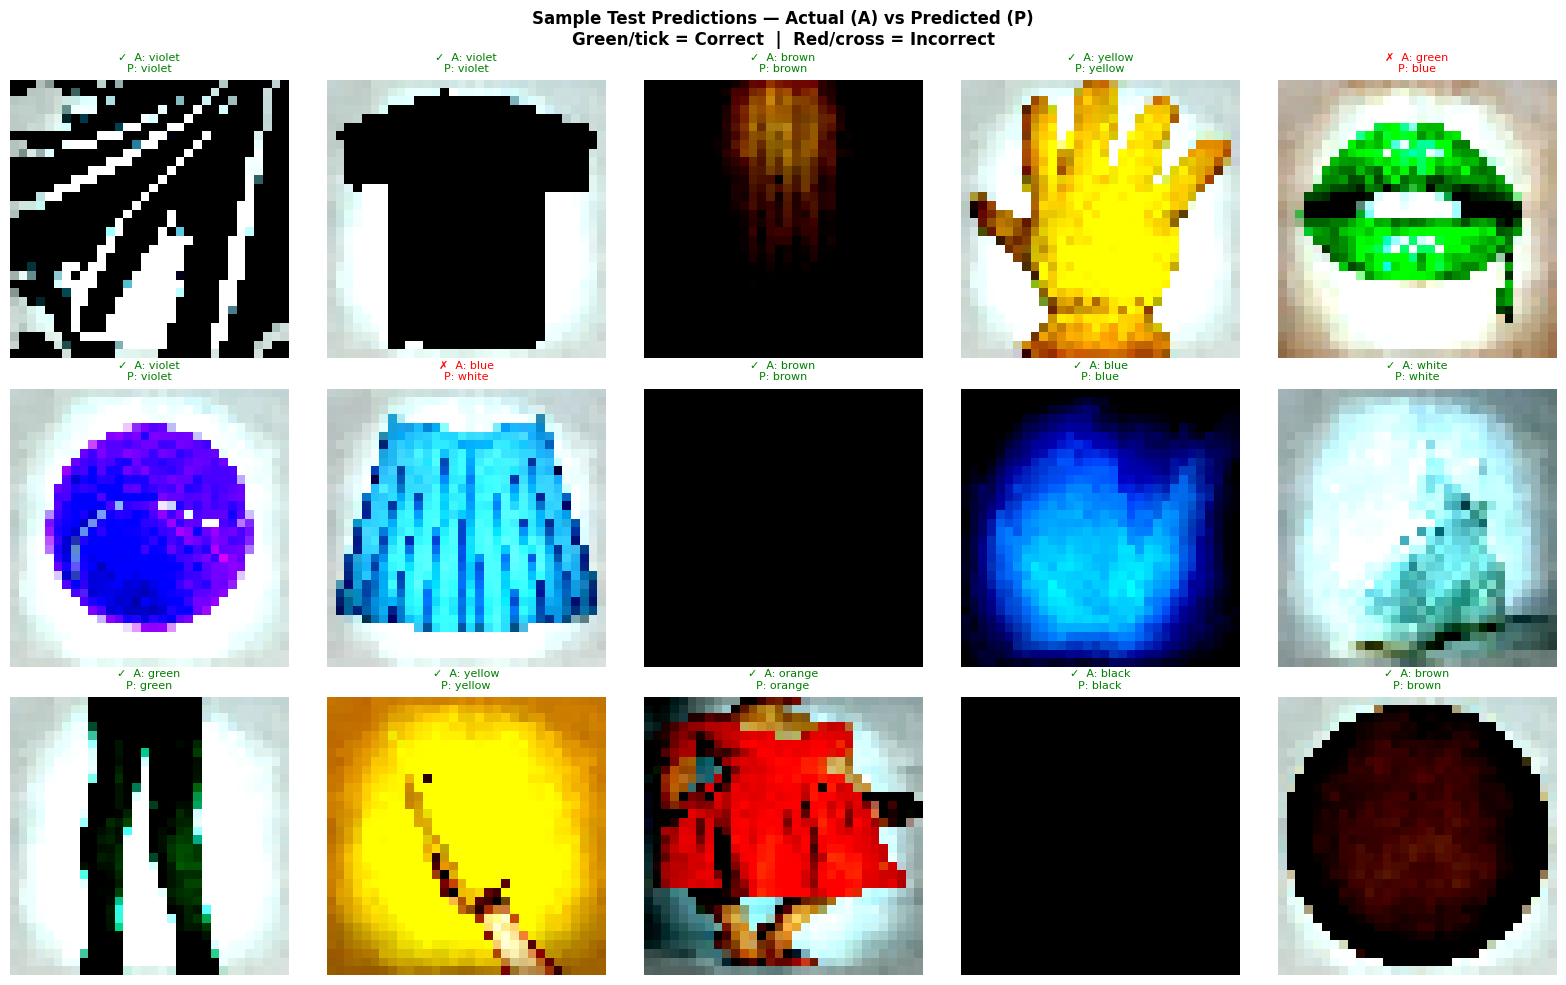

In [60]:
# Display 15 random test images with actual vs predicted labels
# (mirrors the reference notebook's visual prediction check)
n_show = 15
pick   = np.random.choice(len(X_c_test), n_show, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
axes = axes.flatten()

for plot_i, idx in enumerate(pick):
    img = X_c_test[idx].reshape(IMG_SIZE, IMG_SIZE, 3)
    actual    = class_names[y_c_test[idx]]
    predicted = class_names[y_c_pred[idx]]
    match     = chr(10003) if actual == predicted else chr(10007)
    color     = 'green' if actual == predicted else 'red'
    axes[plot_i].imshow(img)
    axes[plot_i].set_title(f'{match}  A: {actual}\nP: {predicted}',
                           fontsize=8, color=color)
    axes[plot_i].axis('off')

plt.suptitle('Sample Test Predictions — Actual (A) vs Predicted (P)\n'
             'Green/tick = Correct  |  Red/cross = Incorrect',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [61]:
# Final Results Summary Table
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1-Score (weighted)'],
    'Score':  [round(accuracy_c,4), round(precision_c,4), round(recall_c,4), round(f1_c,4)]
})
print(summary.to_string(index=False))


              Metric  Score
            Accuracy 0.8750
Precision (weighted) 0.8917
   Recall (weighted) 0.8750
 F1-Score (weighted) 0.8685


---
## Summary

| Task | Model | Key Metrics |
|------|-------|-------------|
| Task 1 — Heart Disease | SVM (default SVC) | Accuracy, Precision, Recall, F1 |
| Task 1 — Hyperparameter Tuning | SVM (linear/rbf/poly/sigmoid, C, gamma) | Comparison table + bar/line plots |
| Task 2 — Color Classification | OneVsOne SVM (linear, C=1) | Weighted Accuracy, Precision, Recall, F1 |

**Libraries Used:** Scikit-learn, Pandas, NumPy, Matplotlib, Pillow
